In [3]:
from matplotlib.colors import LogNorm
import seaborn as sns
import numpy as np
import pandas as pd
from utils_data import repeat, melt_and_keep
from utils_plot import df_vals, log_relplot
from sparse_recov import perform_log_least_squares_fit, add_log_fit_line_to_plot, plot_on_facets
import matplotlib.pyplot as plt
from ydata_profiling import ProfileReport


In [74]:
df= pd.read_pickle("../data/jan_2025_32.pickle")
# df= pd.read_pickle("../dataylastdf.pickle")
#profile = ProfileReport(df, title="Profiling Report")
#profile.to_notebook_iframe()

In [13]:
thetime = df['runtime_seconds'].describe()
print(thetime.mean())
(15*60)/thetime.mean() 

200.10520778137123


np.float64(4.497634069490646)

In [71]:
df_vals(df)

'm':
min: 100.00, max: 262144.00, mean: 42734.17, std: 75598.04
----------------------------------------
'k':
[60]
----------------------------------------
'sigma':
[0.    0.001 0.01  0.1   0.3   1.   ]
----------------------------------------
'img':
Categorical:  ['camera']
Categories (2, object): ['phantom', 'camera']
----------------------------------------
'sampling_type':
Categorical:  ['wr']
Categories (2, object): ['wr', 'Ber']
----------------------------------------
'adapted_sampling':
[ True]
----------------------------------------
'alg':
- bpdn_projected
----------------------------------------
'seed':
min: 26665356.00, max: 4282907639.00, mean: 2177725088.70, std: 1260807561.09
----------------------------------------
're':
min: 0.00, max: 5552734.54, mean: 50625.00, std: 388893.24
----------------------------------------
'runtime_seconds':
min: 0.73, max: 67.57, mean: 6.11, std: 10.31
----------------------------------------
'indices':
unhashable type: 'numpy.ndarray'
---

/Users/matthewscott/Prog/Sparse_adapted_denoising/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


/Users/matthewscott/Prog/Sparse_adapted_denoising/sparse_recov/data_analysis.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = df_filtered.groupby(group_cols)


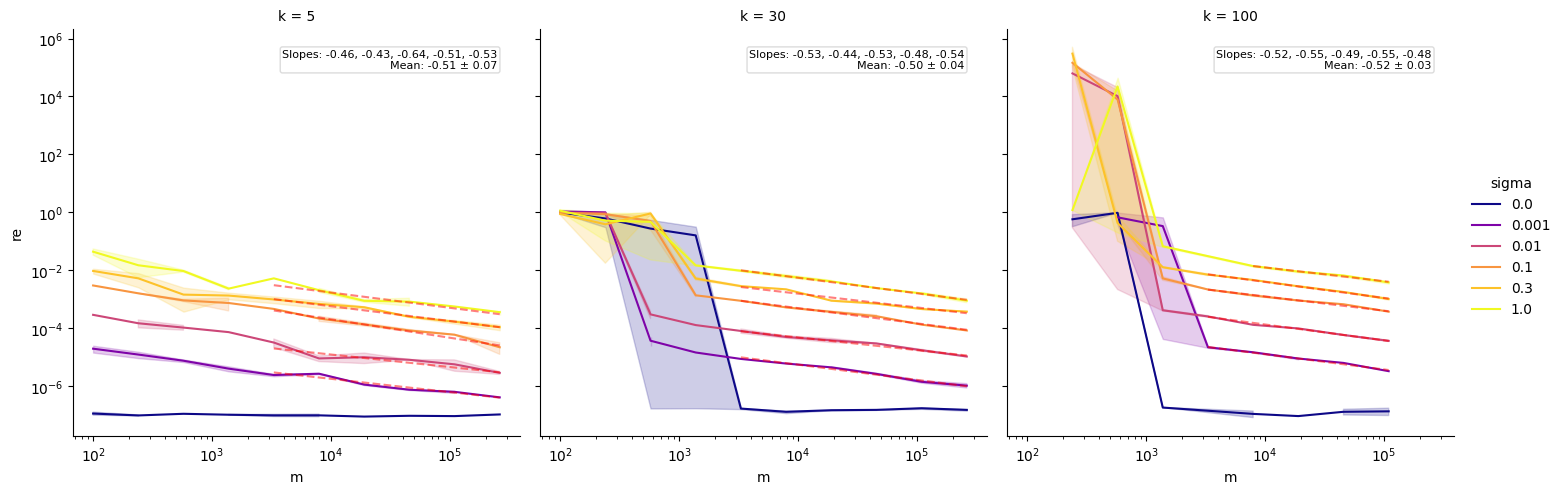

In [15]:
mydf = df[(df['adapted_sampling']==True)&(df['alg']=='bpdn_projected')]

fit_df = perform_least_squares_fit(
    mydf[mydf['sigma'] > 1e-4],
    x_col='m',
    y_col='re',
    group_cols=['k', 'sigma', 'alg', 'img', 'sampling_type', 'adapted_sampling'],
    min_x=10**3.2
)


# Create the main plot
g = sns.relplot(
    data=mydf,
    kind="line",
    x="m",
    y="re",
    col = 'k',
    palette="plasma",
    hue="sigma",
    hue_norm=LogNorm(vmin=1e-4, clip=True),
    errorbar="se"
)

g.set(xscale="log", yscale="log")

plot_on_facets(add_fit_lines_to_plot, g, fit_df, col_label="k", row_label="alg")

plt.show()


In [73]:
df['preconditionned_optimization'].unique()

array([False])

In [16]:
df=df[df['m']> 10**(2.5)]
# df=df[df['adapted_sampli']]

In [17]:
df['m'].unique()

array([   575,   1379,   3306,   7928,  19012,  45589, 109321, 262144])

In [18]:
df[df['m']== df['m'].unique()[0]][df['sigma']==0].shape

/var/folders/9d/dmf_3v3d5cg6drc619z979yc0000gn/T/ipykernel_75682/146882140.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df['m']== df['m'].unique()[0]][df['sigma']==0].shape


(27, 18)

-1.11
-0.67
-0.53
-0.53
-0.54


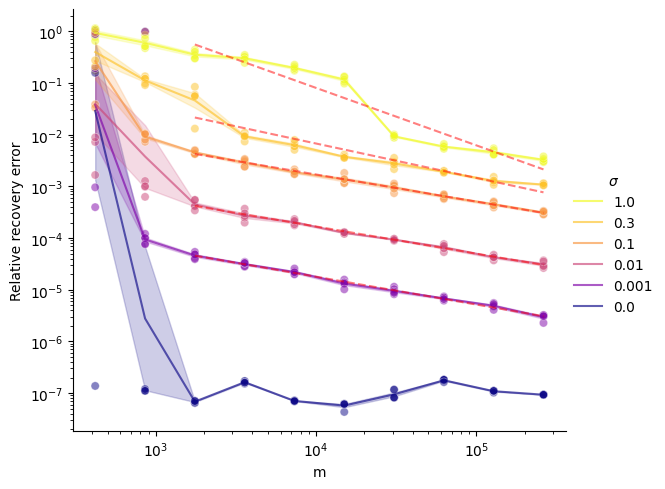

In [28]:
# df_wr = df[df['sampling_type']=='wr']
# mydf = df_wr[df_wr['adapted_sampling']==True]
# mydf = df_wr[mydf['img']=="phantom"]
# doubledf = melt_and_keep(df, ["re","emp_snr"])
# g = sns.relplot(doubledf, kind = "line", x = "m", y="value", row ="variable", col="k", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False}
%matplotlib inline
df= pd.read_pickle("../data/jan_2025_32.pickle")
df = df[df['m']> 300]
g = log_relplot(df, kind = "line", x = "m", y="re", hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", alpha=0.65)
g.map(sns.scatterplot, 'm', 're',data=df, hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", alpha = 0.5)
# Get the current legend handles and labels from the FacetGrid's legend
handles = g.legend.get_lines()  # or get_patches() if the legend uses patches
labels = [t.get_text() for t in g.legend.get_texts()]

# Reverse the handles and labels
handles = handles[::-1]
labels = labels[::-1]

# Remove the existing legend
g.legend.remove()

# Add the reversed legend back
g.add_legend(handles=handles, labels=labels, title=r'$\sigma$', loc='center right')

fits = perform_log_least_squares_fit(df[df['sigma'] > 0], 'm', 're', 'sigma', 1000)
fits['slope'][::-1].map(lambda x: print("{:.2f}".format(x)))

add_log_fit_line_to_plot(fits, g.ax, annotate_slopes=False)
plt.ylabel("Relative recovery error")
plt.title("")
# for ax in g.axes.flat:
#     ax.set_yscale('log')  # Set y-axis to log scale
# plt.yscale('log')  # Set y-axis to log scale
# plt.xscale("log")
plt.savefig("sparse_recov.pdf")
#doubledf=melt_and_keep(mydf, ["re","unique_meas"])

In [24]:
print(df[(df['m'] == df['m'].unique()[1])&(df['sigma']==0)]['re'].max())
print(df[(df['m'] == df['m'].unique()[1])&(df['sigma']==df['sigma'].unique()[2])]['re'].max())

0.9899773411105822
0.9842946575156681


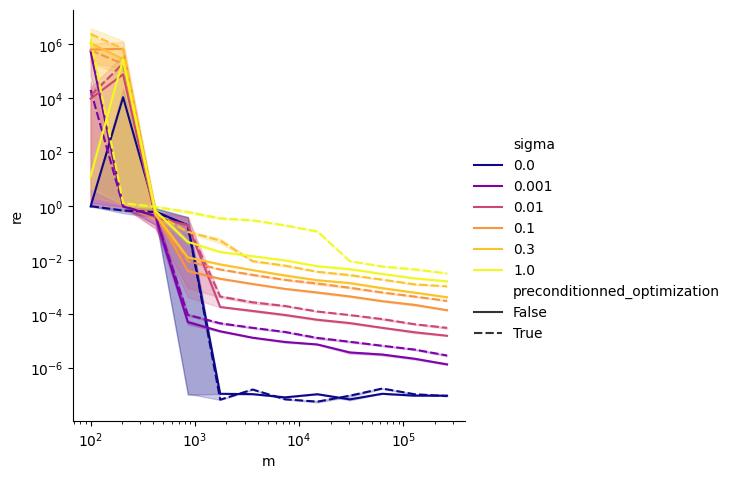

In [91]:
both_precond = pd.concat([pd.read_pickle("../data/jan_2025_31.pickle"),pd.read_pickle("../data/jan_2025_32.pickle")])
g = sns.relplot(both_precond, kind = "line", x = "m", y="re", hue="sigma", style="preconditionned_optimization", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se")
plt.yscale('log')  # Set y-axis to log scale
plt.xscale("log")

In [41]:
df.columns

Index(['m', 'k', 'sigma', 'img', 'sampling_type', 'adapted_sampling',
       'preconditionned_optimization', 'alg', 'seed', 're', 'runtime_seconds',
       'indices', 'experiment_fn_label', 'm_tld', 'emp_snr', 'noise_mag',
       'signal_mag', 'ERROR'],
      dtype='object')

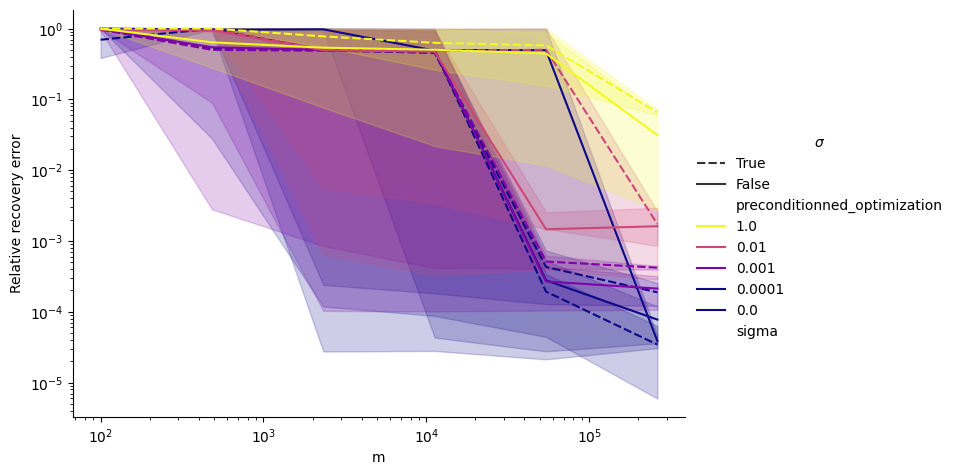

In [60]:
# df_wr = df[df['sampling_type']=='wr']
# mydf = df_wr[df_wr['adapted_sampling']==True]
# mydf = df_wr[mydf['img']=="phantom"]
# doubledf = melt_and_keep(df, ["re","emp_snr"])
# g = sns.relplot(doubledf, kind = "line", x = "m", y="value", row ="variable", col="k", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False}
%matplotlib inline
df= pd.read_pickle("../data/jan_2025_20.pickle")
if "alg" in df.columns:
    mydf = df[df["alg"]== "bpdn_projected"]
g = sns.relplot(mydf, kind = "line", x = "m", y="re", style="preconditionned_optimization", col='k',  hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se")
# Get the current legend handles and labels from the FacetGrid's legend
handles = g.legend.get_lines()  # or get_patches() if the legend uses patches
labels = [t.get_text() for t in g.legend.get_texts()]

# Reverse the handles and labels
handles = handles[::-1]
labels = labels[::-1]

# Remove the existing legend
g.legend.remove()

# Add the reversed legend back
g.add_legend(handles=handles, labels=labels, title=r'$\sigma$', loc='center right')

# fits = perform_least_squares_fit(mydf, 'm', 're', ['alg', 'k', 'sigma'], 1000)
# plot_on_facets(add_fit_lines_to_plot, g, fits, 'alg', 'k')
plt.ylabel("Relative recovery error")
plt.title("")
# for ax in g.axes.flat:
#     ax.set_yscale('log')  # Set y-axis to log scale
plt.yscale('log')  # Set y-axis to log scale
plt.xscale("log")
plt.savefig("sparse_recov.pdf")
#doubledf=melt_and_keep(mydf, ["re","unique_meas"])

In [ ]:
melt_and_keep(df, ["re","emp_snr"]).columns

Index(['m', 'k', 'sigma', 'img', 'sampling_type', 'adapted_sampling',
       'preconditionned_optimization', 'alg', 'seed', 'runtime_seconds',
       'indices', 'experiment_fn_label', 'm_tld', 'noise_mag', 'signal_mag',
       'experiment_found', 'variable', 'value'],
      dtype='object')

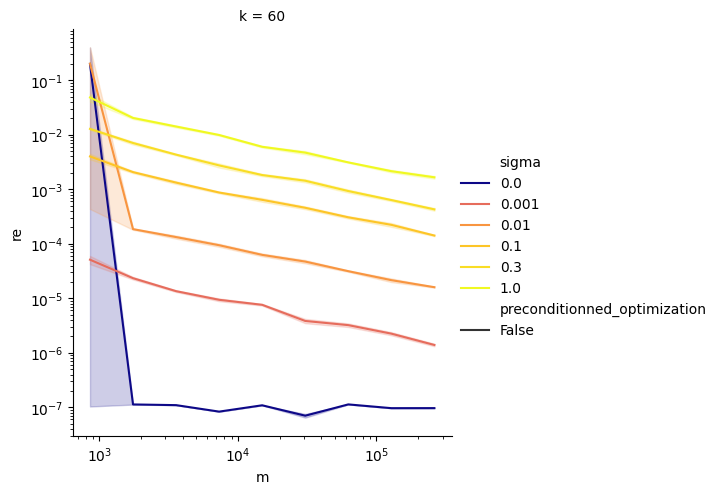

In [ ]:
sns.relplot(df, kind = "line", x = "m", y="re", col="k", style="preconditionned_optimization", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se")
plt.xscale("log")
plt.yscale("log")

In [ ]:
%matplotlib inline
g = sns.relplot(doubledf, kind = "line", x = "m", y="value", col="k", row="variable", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False})
for ax in g.axes.flat:
    ax.set_yscale('log')  # Set y-axis to log scale
plt.xscale("log")

NameError: name 'doubledf' is not defined

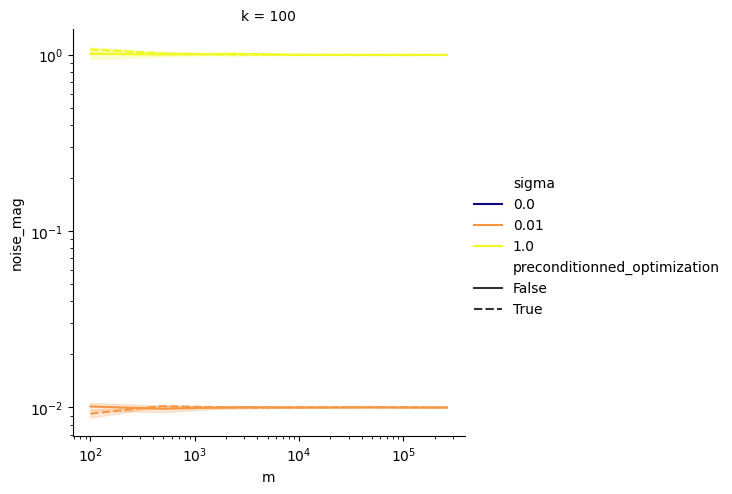

In [ ]:
sns.relplot(df, kind = "line", x = "m", y="noise_mag", col="k", style="preconditionned_optimization", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se")
plt.xscale('log')
plt.yscale('log')

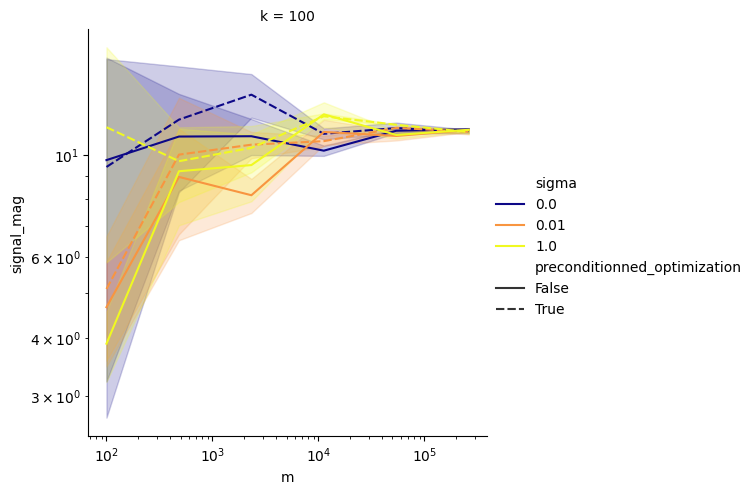

In [ ]:
sns.relplot(df, kind = "line", x = "m", y="signal_mag", col="k", style="preconditionned_optimization", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se")
plt.xscale('log')
plt.yscale('log')

In [ ]:
kkjdf_wr

NameError: name 'kkjdf_wr' is not defined